# QQQ regime experiment, stage 1

Data alignment and exploratory PCA for a frozen model trained through 2018-12-31.

This notebook reads `data/asset_indicator_matrix.csv` and does not write it. A new file hash is archived under `AI-trades/data/`. The saved PCA is not refit. This notebook does not select a component count, fit clusters, estimate a Markov matrix, or emit a trade. Run it from the repository root.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
if (cwd / "ai_trades").is_dir():
    root = cwd
elif (cwd / "AI-trades" / "ai_trades").is_dir():
    root = cwd / "AI-trades"
else:
    raise FileNotFoundError("run this notebook from the repository root or from AI-trades")
sys.path.insert(0, str(root))

from ai_trades.constants import FEATURE_SOURCE
from ai_trades.data_prep import load_feature_matrix
from ai_trades.stage1 import run_stage1

features = load_feature_matrix(FEATURE_SOURCE)
print(FEATURE_SOURCE)
print(features.shape, features.index.min().date(), features.index.max().date())
result = run_stage1()
print(result["model_version"])
print("source hash", result["feature_source_sha256"])
print("archived", result["snapshot_file"], "new copy", result["snapshot_created"])
print("retention rule selected:", result["retention_rule_selected"])

/Users/raynorananta/Documents/projects/voltes/data/asset_indicator_matrix.csv
(6025, 228) 2002-12-04 2026-11-17


stage1_train2018_v1
source hash 4ecefa23bb0321deea57d55a05bc45cba11424ba852554ae40b1e3666ed457ad
archived feature_matrix_v1.csv new copy False
retention rule selected: None


## Alignment and preprocessing

The notebook reads `data/asset_indicator_matrix.csv`. QQQ adjusted prices live in a separate file. The training fit uses rows through 2018-12-31 and is not repeated when the source hash is unchanged.

In [2]:
alignment = pd.Series(result["alignment"])
features = pd.Series({key: value for key, value in result["features"].items() if key != "indicators"})
display(alignment.to_frame("value"))
display(features.to_frame("value"))
print("indicators:", ", ".join(result["features"]["indicators"]))

,value
feature_start,2002-12-04
feature_end,2026-11-17
n_feature_rows,6025
n_feature_columns,228
price_start,1999-03-10
price_end,2026-11-17
n_price_rows,6967
n_intersection,6025
n_feature_dates_missing_qqq,0
feature_dates_missing_qqq_head,[]


,value
assets,"[SPY, QQQ, IWM, TLT, ^VIX, DX-Y.NYB]"
n_indicators_per_asset,"{'SPY': 38, 'QQQ': 38, 'IWM': 38, 'TLT': 38, '..."
indicators_identical_across_assets,True
missing_values,0
infinite_values,0
n_train,4044
n_test,1981
train_start,2002-12-04
train_end,2018-12-31
test_start,2019-01-02


indicators: ADX, Aroon Oscillator, Average True Range, Bollinger Bands_upperband, Bollinger Bands_middleband, Bollinger Bands_lowerband, Chande Momentum Oscillator, Commodity Channel Index, Directional Movement, Exponential Moving Average, Kaufman Adaptive Moving Average, Linear Regression, Linear Regression Indicator, MACD Histogram, MACD Indicator, MACD Percentage, Median Price, Momentum Indicator, Moving Average, Parabolic SAR, Price Differential, Price Ratio, Rate of Change (Price), Relative Strength Index (RSI), Standard Deviation Channels, Stochastic Oscillator_slowk, Stochastic Oscillator_slowd, Stochastic RSI_fastk, Stochastic RSI_fastd, The Moving Average Oscillator, Triple Exponential Moving Average, TRIX Indicator, True Range, Typical Price, Ultimate Oscillator, Weighted Close, Weighted Moving Average, Williams %R


## Training PCA and retention rules

Rules are compared on the training spectrum. The Marchenko–Pastur count is one candidate, not the default kept set. Cumulative-variance cutoffs are also candidates. Nothing in this table is chosen from test-period returns.

,rule,n_components,variance_share,smallest_kept_eigenvalue,definition
0,kaiser_eigenvalue_gt_1,25.0,0.907065,1.079557,correlation eigenvalue above 1
1,mp_sigma2_1,19.0,0.874216,1.671152,above (1+sqrt(gamma))^2 = 1.531269 with sigma^...
2,mp_iterated_sigma2,NaN,NaN,NaN,not used: bulk mean collapsed toward zero beca...
3,cumulative_variance_80,12.0,0.809966,3.148822,smallest leading count whose eigenvalue share ...
4,cumulative_variance_90,24.0,0.902330,1.105747,smallest leading count whose eigenvalue share ...
5,cumulative_variance_95,40.0,0.951889,0.452988,smallest leading count whose eigenvalue share ...
6,all_components_diagnostic_only,228.0,1.000000,0.000000,full training basis; not a retention choice


p=228  gamma=0.0564  MP edge at sigma^2=1 is [0.581, 1.531]  iterated sigma^2=None converged=False  largest eigenvalue=62.03  participation ratio=7.9
eigenvalue check, max abs difference vs sklearn: 9.237e-14


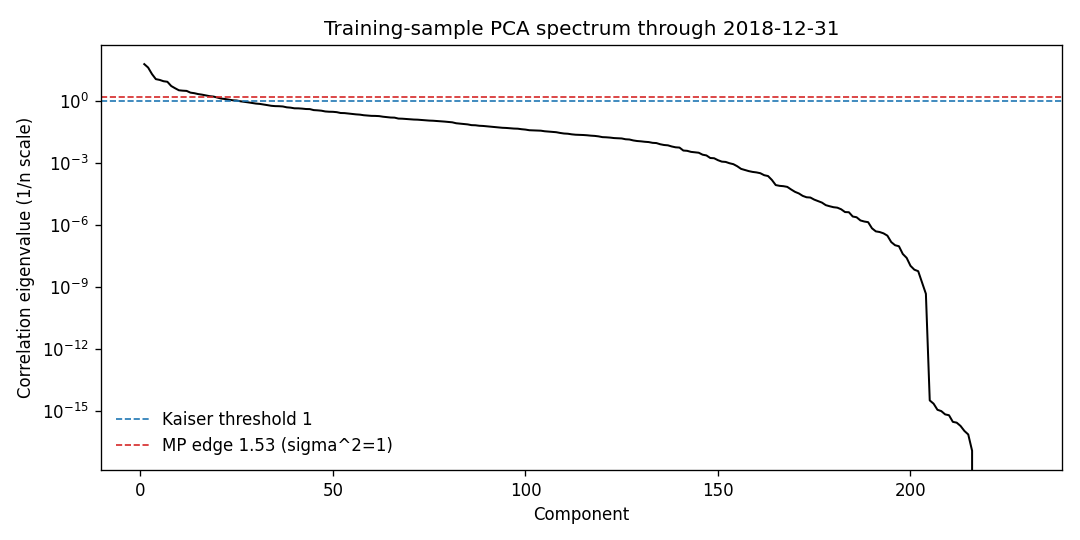

In [3]:
retention = pd.DataFrame(result["retention"])
display(retention)
lower, upper = result["mp_edge_sigma2_1"]
print(
    f"p={result['n_features']}  gamma={result['gamma']:.4f}  "
    f"MP edge at sigma^2=1 is [{lower:.3f}, {upper:.3f}]  "
    f"iterated sigma^2={result['iterated_noise']['sigma2']} "
    f"converged={result['iterated_noise']['converged']}  "
    f"largest eigenvalue={result['largest_eigenvalue']:.2f}  "
    f"participation ratio={result['participation_ratio']:.1f}"
)
print(
    "eigenvalue check, max abs difference vs sklearn:",
    f"{result['consistency']['max_abs_difference']:.3e}",
)
display(Image(filename=str(Path(result["report_dir"]) / "stage1_scree_v1.png")))

## Frozen transform of the later sample

Test rows are standardized and projected with the training scaler and loadings. Means near zero and scales near the training scale would mean the leading scores did not shift. A shift is reported here and is not used to pick a component count.

In [4]:
display(pd.DataFrame(result["score_shift"]))
display(pd.DataFrame(result["column_shift"]))
print(
    "Stage 1 stops here. No K-means, no transition matrix, no return table, and no order."
)

,component,train_mean,train_std,test_mean,test_std
0,1,0.000000e+00,7.876003,39.017999,14.600259
1,2,5.622494e-17,6.510234,-7.928617,11.563872
2,3,0.000000e+00,4.532213,5.582233,6.034565
3,4,-5.622494e-17,3.418738,0.411891,3.319117
4,5,-4.216871e-17,3.269540,-3.580650,3.994359


,column,test_mean_z,test_std_z
0,QQQ|Average True Range,9.244763,5.051515
1,QQQ|Bollinger Bands_upperband,8.002013,3.916909
2,QQQ|Weighted Close,7.950106,3.904430
3,QQQ|Typical Price,7.949976,3.904536
4,QQQ|Median Price,7.949648,3.904793
5,QQQ|Linear Regression Indicator,7.949286,3.907458
6,QQQ|Triple Exponential Moving Average,7.948430,3.912449
7,QQQ|Linear Regression,7.948247,3.906065
8,QQQ|Bollinger Bands_middleband,7.946434,3.903900
9,QQQ|Kaufman Adaptive Moving Average,7.937741,3.899923


Stage 1 stops here. No K-means, no transition matrix, no return table, and no order.


## Stage 2, price-relative PCA

Adjusted closes are checked against the prices main.py uses. Level columns become L/C - 1. Width columns become V/C. The Stage 1 model is left as saved.

stage2_price_relative_train2018_v1
retention rule selected: None


,stage1_raw,stage2_transformed
largest_eigenvalue,62.031,61.138
participation_ratio,7.867,9.596
pc1_test_mean,39.018,-0.384
max_abs_column_mean_z,9.245,0.746


,rule,n_components,variance_share,smallest_kept_eigenvalue,definition
0,kaiser_eigenvalue_gt_1,30.0,0.896775,1.019836,correlation eigenvalue above 1
1,mp_sigma2_1,23.0,0.858493,1.538483,above (1+sqrt(gamma))^2 = 1.531269 with sigma^...
2,mp_iterated_sigma2,NaN,NaN,NaN,not used: bulk mean collapsed toward zero beca...
3,cumulative_variance_80,17.0,0.810343,2.390305,smallest leading count whose eigenvalue share ...
4,cumulative_variance_90,31.0,0.901015,0.966847,smallest leading count whose eigenvalue share ...
5,cumulative_variance_95,49.0,0.950467,0.415268,smallest leading count whose eigenvalue share ...
6,all_components_diagnostic_only,228.0,1.000000,0.000000,full training basis; not a retention choice


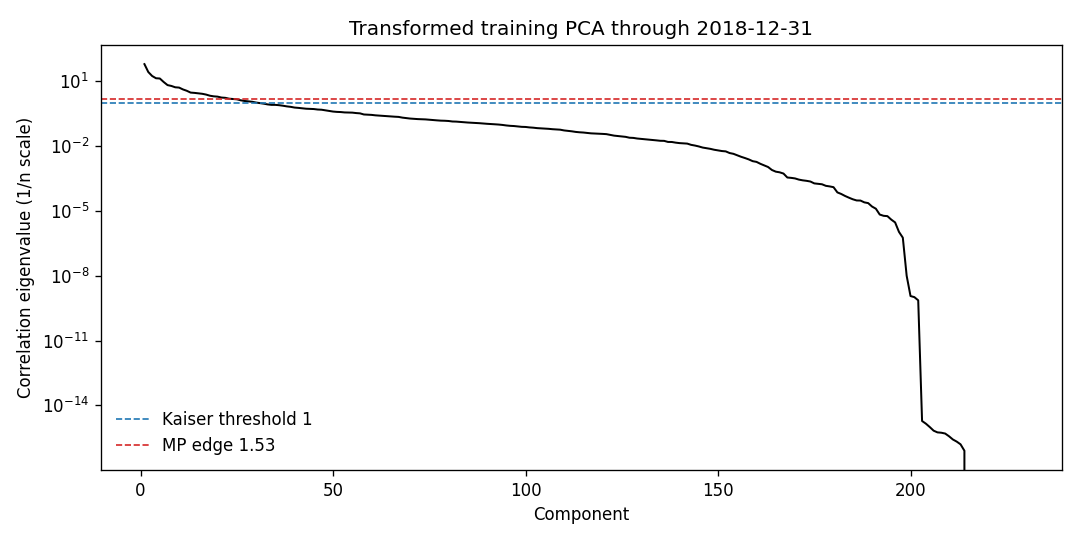

Stage 2 stops here. No K-means, no Markov matrix, and no order.


In [5]:
from ai_trades.stage2 import run_stage2
from IPython.display import Image, display
from pathlib import Path
import pandas as pd

stage2 = run_stage2()
print(stage2['model_version'])
print('retention rule selected:', stage2['retention_rule_selected'])
comparison = pd.DataFrame({
    'stage1_raw': {
        'largest_eigenvalue': stage2['baseline']['largest_eigenvalue'],
        'participation_ratio': stage2['baseline']['participation_ratio'],
        'pc1_test_mean': stage2['baseline']['pc1_test_mean'],
        'max_abs_column_mean_z': stage2['baseline_max_abs_mean_z'],
    },
    'stage2_transformed': {
        'largest_eigenvalue': stage2['transformed']['largest_eigenvalue'],
        'participation_ratio': stage2['transformed']['participation_ratio'],
        'pc1_test_mean': stage2['transformed']['pc1_test_mean'],
        'max_abs_column_mean_z': stage2['transformed_max_abs_mean_z'],
    },
})
display(comparison.round(3))
display(pd.DataFrame(stage2['transformed']['retention']))
display(Image(filename=str(Path(stage2['report_dir']) / 'stage2_scree_v1.png')))
print('Stage 2 stops here. No K-means, no Markov matrix, and no order.')
